In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

El cliente exige adelantar la entrega de un proyecto de montaje industrial **3 semanas**. El cuadro de prelaciones, las duraciones (semanas), las duraciones mínimas alcanzables, el coste unitario de reducción (`ucr`, k€ por semana) y las **emisiones adicionales** de cada semana que se acorta (`emisiones_reduccion`, t CO₂ por semana: grupos electrógenos para el doble turno, transporte aéreo de componentes, hormigón de fraguado rápido) se adjuntan.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr, emisiones_reduccion
    ('A'     , '---'      , 8       , 6           , 3  , 12                 ),
    ('B'     , '---'      , 4       , 1           , 5  , 8                  ),
    ('C'     , '---'      , 7       , 5           , 1  , 4                  ),
    ('D'     , 'A,B,C'    , 3       , 2           , 4  , 0                  ),
    ('E'     , 'B'        , 1       , 1           , 0  , 20                 ),
    ('F'     , 'E'        , 7       , 4           , 3  , 8                  ),
    ('G'     , 'C'        , 1       , 1           , 0  , 0                  ),
    ('H'     , 'D,G'      , 8       , 6           , 7  , 0                  ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr', 'emisiones_reduccion']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr,emisiones_reduccion
activity,,,,,
A,---,8,6,3,12
B,---,4,1,5,8
C,---,7,5,1,4
D,"A,B,C",3,2,4,0
E,B,1,1,0,20
F,E,7,4,3,8
G,C,1,1,0,0
H,"D,G",8,6,7,0


La organización tiene fijado en su política un **precio sombra del carbono de 300 €/t CO₂** para las decisiones de proyecto. En el mercado voluntario hay créditos de compensación a 8 €/t.

> **De: Director de operaciones**
> Comprime por el método de siempre: Ackoff con los costes unitarios y listo, que es lo más barato. Las toneladas que salgan las compensamos con créditos a 8 €/t y el proyecto queda «neutro». El precio sombra es para la memoria de sostenibilidad, no para la obra.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el plan de reducción de 3 semanas de menor coste monetario (sin precio del carbono): actividades acortadas en cada paso, coste y emisiones adicionales del plan.  "
pregunta_2 = "2. (A) Repita el algoritmo con el coste unitario total (ucr + emisiones × 300 €/t) y compare los dos planes: coste monetario, emisiones y coste total al precio sombra. ¿Cuánto costaría compensar las emisiones de cada plan a 8 €/t y cuánto valen al precio sombra?  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿qué plan es el correcto y por qué el argumento «compensamos a 8 €/t» no cambia la respuesta? ¿En qué escalón de la pirámide está cada propuesta?  "
pregunta_4 = "4. (C) ¿Qué propone al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el plan de reducción de 3 semanas de menor coste monetario (sin precio del carbono): actividades acortadas en cada paso, coste y emisiones adicionales del plan.  

2. (A) Repita el algoritmo con el coste unitario total (ucr + emisiones × 300 €/t) y compare los dos planes: coste monetario, emisiones y coste total al precio sombra. ¿Cuánto costaría compensar las emisiones de cada plan a 8 €/t y cuánto valen al precio sombra?  

3. (B) Según los criterios de referencia, ¿qué plan es el correcto y por qué el argumento «compensamos a 8 €/t» no cambia la respuesta? ¿En qué escalón de la pirámide está cada propuesta?  

4. (C) ¿Qué propone al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
semanas_pedidas, precio_sombra, precio_creditos = 3, 300, 8
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
datos_proyecto['ucr_total'] = datos_proyecto['ucr'] + datos_proyecto['emisiones_reduccion'] * precio_sombra / 1000
def resumen_plan(pasos):
    acts = [a for paso in pasos.values() for a in paso]
    coste = float(datos_proyecto.loc[acts, 'ucr'].sum())
    emisiones = float(datos_proyecto.loc[acts, 'emisiones_reduccion'].sum())
    return pd.Series({'coste monetario (k€)': coste, 'emisiones adicionales (t CO₂)': emisiones,
                      'valor al precio sombra (k€)': emisiones * precio_sombra / 1000,
                      'coste total al precio sombra (k€)': coste + emisiones * precio_sombra / 1000,
                      'compensar a precio de créditos (k€)': emisiones * precio_creditos / 1000})

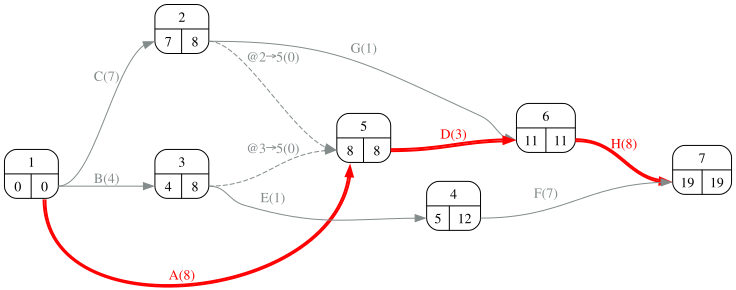

In [8]:
#| fig-cap: "Grafo PERT con el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Cálculo de los tiempos tempranos y tardíos de los sucesos paso a paso (avance con los botones):

In [7]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

**Tiempos tempranos (hacia delante)**

- $t_{1} = 0$
- $t_{2} = 0+7 = 7$ &nbsp; (C)
- $t_{3} = 0+4 = 4$ &nbsp; (B)
- $t_{4} = 4+1 = 5$ &nbsp; (E)
- $t_{5} = \max\{7+0,\ 4+0,\ 0+8\} = 8$ &nbsp; (@2→5, @3→5, A)
- $t_{6} = \max\{8+3,\ 7+1\} = 11$ &nbsp; (D, G)
- $t_{7} = \max\{5+7,\ 11+8\} = 19$ &nbsp; (F, H)

**Tiempos tardíos (hacia atrás)**

- $t_{7}^{*} = t_{7} = 19$
- $t_{6}^{*} = 19-8 = 11$ &nbsp; (H)
- $t_{5}^{*} = 11-3 = 8$ &nbsp; (D)
- $t_{4}^{*} = 19-7 = 12$ &nbsp; (F)
- $t_{3}^{*} = \min\{8-0,\ 12-1\} = 8$ &nbsp; (@3→5, E)
- $t_{2}^{*} = \min\{8-0,\ 11-1\} = 8$ &nbsp; (@2→5, G)
- $t_{1}^{*} = \min\{8-8,\ 8-4,\ 8-7\} = 0$ &nbsp; (A, B, C)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el plan de reducción de 3 semanas de menor coste monetario (sin precio del carbono): actividades acortadas en cada paso, coste y emisiones adicionales del plan.  

In [10]:
#| tbl-cap: "Ackoff-Sasieni con el coste unitario monetario"
#| label: tbl-ackoffDinero
tabla_1, pasos_1, duraciones_1, margen_1 = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=semanas_pedidas, report=False)
proyecto.display_ackoff_pasos(
    durations=datos_proyecto['duration'],
    min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'],
    reduction=semanas_pedidas)

,A,B,C,D,E,F,G,H,0,1,2,3
Route_1,3.0,,,4.0,,,,7.0,19.0,18.0,17.0,16.0
Route_2,,5.0,,4.0,,,,7.0,15.0,15.0,15.0,14.0
Route_3,,5.0,,,0.0,3.0,,,12.0,12.0,12.0,12.0
Route_4,,,1.0,4.0,,,,7.0,18.0,18.0,17.0,16.0
Route_5,,,1.0,,,,0.0,7.0,16.0,16.0,15.0,15.0
0,2.0,3.0,2.0,1.0,0.0,3.0,0.0,2.0,,,,
1,1.0,3.0,2.0,1.0,0.0,3.0,0.0,2.0,,,,
2,0.0,3.0,1.0,1.0,0.0,3.0,0.0,2.0,,,,
3,0.0,3.0,1.0,0.0,0.0,3.0,0.0,2.0,,,,


In [11]:
#| tbl-cap: "Opciones consideradas en cada paso (coste monetario)"
#| label: tbl-ackoffPaso1
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos_1)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,19,Route_1,A (3); D (4); H (7),A,3.0
2,18,"Route_1, Route_4",D (4); A+C (4); H (7),"A, C",4.0
3,17,"Route_1, Route_4",D (4); H (7),D,4.0


In [12]:
plan_1 = resumen_plan(pasos_1)
display(plan_1.round(2).to_frame('plan 1: coste monetario').T)
Markdown('Plan 1: ' + '; '.join('paso ' + str(k + 1) + ': ' + ', '.join(v) for k, v in sorted(pasos_1.items())) + f'''. Coste **{plan_1.iloc[0]:.0f} k€** y **{plan_1.iloc[1]:.0f} t CO₂** adicionales.''')

,coste monetario (k€),emisiones adicionales (t CO₂),valor al precio sombra (k€),coste total al precio sombra (k€),compensar a precio de créditos (k€)
plan 1: coste monetario,11.0,28.0,8.4,19.4,0.22


Plan 1: paso 1: A; paso 2: A, C; paso 3: D. Coste **11 k€** y **28 t CO₂** adicionales.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Repita el algoritmo con el coste unitario total (ucr + emisiones × 300 €/t) y compare los dos planes: coste monetario, emisiones y coste total al precio sombra. ¿Cuánto costaría compensar las emisiones de cada plan a 8 €/t y cuánto valen al precio sombra?  

In [14]:
#| tbl-cap: "Ackoff-Sasieni con el coste unitario total (ucr + emisiones × precio sombra)"
#| label: tbl-ackoffTotal
tabla_2, pasos_2, duraciones_2, margen_2 = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr_total'], reduction=semanas_pedidas, report=False)
proyecto.display_ackoff_pasos(
    durations=datos_proyecto['duration'],
    min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr_total'],
    reduction=semanas_pedidas)

,A,B,C,D,E,F,G,H,0,1,2,3
Route_1,6.6,,,4.0,,,,7.0,19.0,18.0,17.0,16.0
Route_2,,7.4,,4.0,,,,7.0,15.0,14.0,14.0,13.0
Route_3,,7.4,,,6.0,5.4,,,12.0,12.0,12.0,12.0
Route_4,,,2.2,4.0,,,,7.0,18.0,17.0,17.0,16.0
Route_5,,,2.2,,,,0.0,7.0,16.0,16.0,16.0,15.0
0,2.0,3.0,2.0,1.0,0.0,3.0,0.0,2.0,,,,
1,2.0,3.0,2.0,0.0,0.0,3.0,0.0,2.0,,,,
2,1.0,3.0,2.0,0.0,0.0,3.0,0.0,2.0,,,,
3,1.0,3.0,2.0,0.0,0.0,3.0,0.0,1.0,,,,


In [15]:
#| tbl-cap: "Opciones consideradas en cada paso (coste total)"
#| label: tbl-ackoffPaso2
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr_total'], pasos_2)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,19,Route_1,D (4); A (7); H (7),D,4.0
2,18,Route_1,A (7); H (7),A,6.6
3,17,"Route_1, Route_4",H (7); A+C (9),H,7.0


In [16]:
#| tbl-cap: "Comparación de los dos planes"
#| label: tbl-planes
plan_2 = resumen_plan(pasos_2)
comparacion = pd.DataFrame({'plan 1 (ucr)': plan_1, 'plan 2 (ucr + carbono)': plan_2})
display(comparacion.round(2))
Markdown('Plan 2: ' + '; '.join('paso ' + str(k + 1) + ': ' + ', '.join(v) for k, v in sorted(pasos_2.items())) + f'''. Cuesta **{plan_2.iloc[0] - plan_1.iloc[0]:.1f} k€ más** en dinero y emite **{plan_1.iloc[1] - plan_2.iloc[1]:.0f} t menos**; al precio sombra el plan 2 es **{plan_1.iloc[3] - plan_2.iloc[3]:.1f} k€ más barato** en total. Compensar el plan 1 a {precio_creditos} €/t costaría {plan_1.iloc[4]:.1f} k€; esas toneladas valen {plan_1.iloc[2]:.1f} k€ al precio sombra.''')

,plan 1 (ucr),plan 2 (ucr + carbono)
coste monetario (k€),11.00,14.0
emisiones adicionales (t CO₂),28.00,12.0
valor al precio sombra (k€),8.40,3.6
coste total al precio sombra (k€),19.40,17.6
compensar a precio de créditos (k€),0.22,0.1


Plan 2: paso 1: D; paso 2: A; paso 3: H. Cuesta **3.0 k€ más** en dinero y emite **16 t menos**; al precio sombra el plan 2 es **1.8 k€ más barato** en total. Compensar el plan 1 a 8 €/t costaría 0.2 k€; esas toneladas valen 8.4 k€ al precio sombra.

El algoritmo es el mismo; cambia el coste unitario con el que se ordenan las opciones. Con el precio del carbono dentro del coste, una semana «barata» en dinero pero cara en emisiones deja de ser la primera opción, y el plan cambia de actividades.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿qué plan es el correcto y por qué el argumento «compensamos a 8 €/t» no cambia la respuesta? ¿En qué escalón de la pirámide está cada propuesta?  

**S2.** La organización ha fijado el precio de la externalidad (300 €/t), de modo que el criterio de decisión es el coste total: el plan 2 (17.6 k€) frente al plan 1 (19.4 k€). El argumento de los créditos a 8 €/t sustituye el precio que la organización ha decidido por el precio que a uno le conviene: si valiera, el precio sombra no serviría para nada. Comprar créditos no reduce las emisiones del proyecto; las compensa, y a un precio que no es el de la política. **S1.** El plan 1 más créditos está en el escalón más bajo de la pirámide (**compensar**); el plan 2 **minimiza** las emisiones de la compresión; **evitar** sería negociar con el cliente las 3 semanas (lección 19, C13 y C10) o acortar por medios sin emisiones (solapes, más personal en jornada ordinaria). La clasificación no es opinable: compensar es compensar.

In [18]:
preguntas_test = [
    ('Con un precio sombra del carbono fijado por la organización, el plan de compresión correcto es…', ['el de menor coste total (dinero + emisiones al precio sombra)', 'el de menor coste monetario, compensando después', 'el de menos emisiones a cualquier coste', 'el que pida el cliente'],
     'S2: la externalidad con precio entra en el coste de la decisión.'),
    ('Comprar créditos de compensación para las emisiones de un plan está, en la pirámide de la sostenibilidad del PMBOK 8, en el escalón…', ['más bajo: compensar', 'de minimizar', 'de restaurar', 'de evitar'],
     'La figura 3-7 ordena compensar < restaurar < minimizar < evitar.'),
    ('Incorporar el precio del carbono a Ackoff-Sasieni consiste en…', ['sumar al coste unitario de reducción las emisiones por semana multiplicadas por el precio', 'restar el precio de los créditos del coste unitario', 'eliminar las actividades con emisiones', 'cambiar el número de semanas pedidas'],
     'El algoritmo no cambia; cambia el coste con el que ordena las opciones.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — compresión con carbono')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — compresión con carbono

::Sostenibilidad 20 — compresión con carbono P1::Con un precio sombra del carbono fijado por la organización, el plan de compresión correcto es… {=el de menor coste total (dinero + emisiones al precio sombra) ~el de menor coste monetario, compensando después ~el de menos emisiones a cualquier coste ~el que pida el cliente ####S2: la externalidad con precio entra en el coste de la decisión.}

::Sostenibilidad 20 — compresión con carbono P2::Comprar créditos de compensación para las emisiones de un plan está, en la pirámide de la sostenibilidad del PMBOK 8, en el escalón… {~de evitar =más bajo: compensar ~de restaurar ~de minimizar ####La figura 3-7 ordena compensar < restaurar < minimizar < evitar.}

::Sostenibilidad 20 — compresión con carbono P3::Incorporar el precio del carbono a Ackoff-Sasieni consiste en… {~cambiar el número de semanas pedidas =sumar al coste unitario de reducción las emisiones por semana multiplicadas por el p

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de operaciones: el plan 2 con sus cifras (cuesta 3.0 k€ más y emite 16 t menos); el precio sombra es la política de la empresa y se aplica en la obra o no es una política. Al cliente: el precio de cada semana con el coste total, y la alternativa de no comprimir o comprimir menos. Prueba de publicidad: ¿pondría en la memoria de sostenibilidad que el proyecto se llamó «neutro» por 0.2 k€ de créditos mientras se elegía el plan que más emitía?